<a href="https://colab.research.google.com/github/keerthh129/AIML-Colab/blob/main/cat_2_dl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install tensorflow scikit-learn

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving DailyDelhiClimateTrain.csv to DailyDelhiClimateTrain.csv


In [6]:
uploaded = files.upload()

Saving DailyDelhiClimateTest.csv to DailyDelhiClimateTest (1).csv


In [7]:
import os

print(os.listdir("/content"))

['.config', 'DailyDelhiClimateTest (1).csv', 'DailyDelhiClimateTrain.csv', 'DailyDelhiClimateTest.csv', 'sample_data']


In [8]:
import pandas as pd

train_df = pd.read_csv("/content/DailyDelhiClimateTrain.csv")
test_df = pd.read_csv("/content/DailyDelhiClimateTest.csv")

df = pd.concat([train_df, test_df], ignore_index=True)

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates("date")
df = df.reset_index(drop=True)

print("Total records:", len(df))
display(df.head())

Total records: 1575


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Convert dates and sort chronologically
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"])
df = df.drop_duplicates(subset=["date"])
df = df.sort_values("date").reset_index(drop=True)

# Select target temperature
target_col = "meantemp"

# Select available weather features
features = [
    col for col in
    ["meantemp", "humidity", "wind_speed", "meanpressure"]
    if col in df.columns
]

# Convert weather columns to numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Interpolate missing weather values
df = df.set_index("date")
df[features] = df[features].interpolate(
    method="time", limit_direction="both"
)
df = df.dropna(subset=features).reset_index()

# Keep the longest consecutive daily block
groups = df["date"].diff().dt.days.ne(1).cumsum()
df["_group"] = groups
group_sizes = df.groupby("_group").size()
longest_group = group_sizes.idxmax()

df = (
    df[df["_group"] == longest_group]
    .drop(columns="_group")
    .reset_index(drop=True)
)

if len(df) < 1000:
    raise ValueError(
        f"Only {len(df)} consecutive daily records found. "
        "Check the dataset dates."
    )

print("Total consecutive records:", len(df))
print("Start date:", df["date"].min().date())
print("End date:", df["date"].max().date())
print("Features:", features)

display(df.head())

Total consecutive records: 1575
Start date: 2013-01-01
End date: 2017-04-24
Features: ['meantemp', 'humidity', 'wind_speed', 'meanpressure']


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


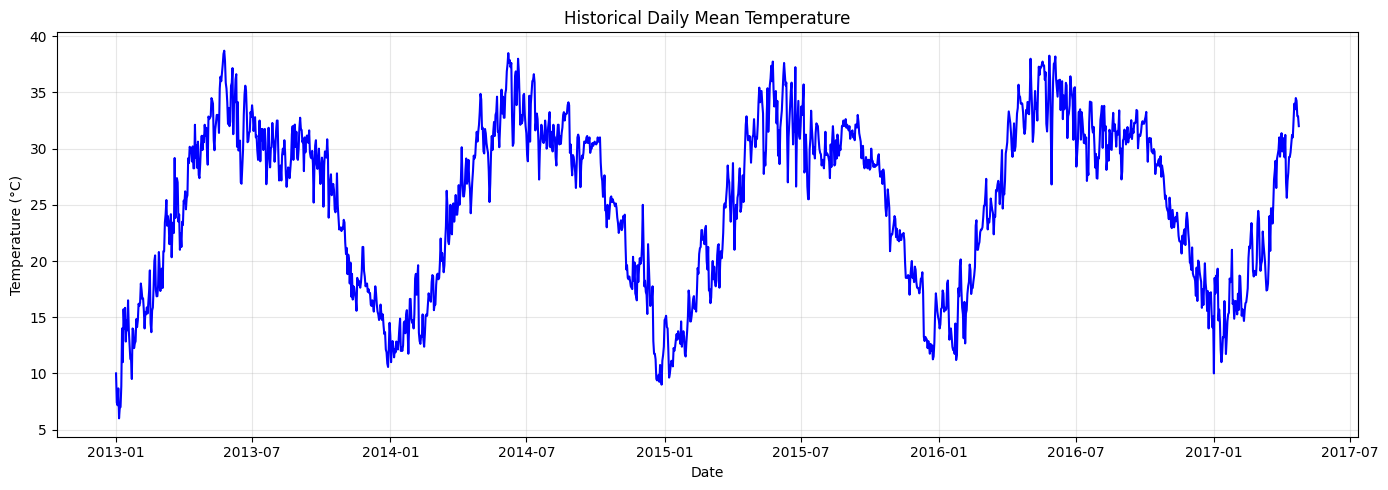

In [10]:
plt.figure(figsize=(14, 5))
plt.plot(df["date"], df["meantemp"], color="blue")
plt.title("Historical Daily Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:

split_idx = int(len(df) * 0.80)

scaler = MinMaxScaler()

scaler.fit(df.iloc[:split_idx][features])

scaled_values = scaler.transform(df[features])

target_idx = features.index(target_col)

print("Training records:", split_idx)
print("Testing records:", len(df) - split_idx)

Training records: 1260
Testing records: 315


In [12]:
LOOKBACK = 30

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(LOOKBACK, len(df)):
    X_seq = scaled_values[i - LOOKBACK:i]
    y_value = scaled_values[i, target_idx]

    if i < split_idx:
        X_train.append(X_seq)
        y_train.append(y_value)
    else:
        X_test.append(X_seq)
        y_test.append(y_value)

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1230, 30, 4)
y_train: (1230,)
X_test: (315, 30, 4)
y_test: (315,)


In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)


model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed successfully!")

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - loss: 0.0677 - mae: 0.2114 - val_loss: 0.0134 - val_mae: 0.0898
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0140 - mae: 0.0946 - val_loss: 0.0088 - val_mae: 0.0806
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0117 - mae: 0.0853 - val_loss: 0.0060 - val_mae: 0.0629
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0116 - mae: 0.0857 - val_loss: 0.0060 - val_mae: 0.0640
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0106 - mae: 0.0812 - val_loss: 0.0055 - val_mae: 0.0601
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0097 - mae: 0.0769 - val_loss: 0.0053 - val_mae: 0.0568
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0097 - mae: 0.0784 - val_loss: 0.0052 - val_mae: 0.0570
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0087 - mae: 0.0748 - val_loss: 0.0056 - val_mae: 0.0605
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - lo

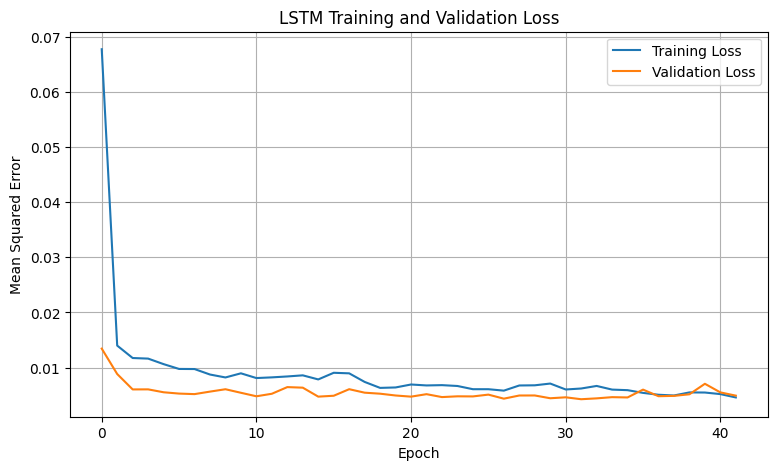

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_pred_scaled = model.predict(X_test, verbose=0)

def inverse_temperature(values):
    values = np.asarray(values).reshape(-1)
    dummy = np.zeros((len(values), len(features)))
    dummy[:, target_idx] = values
    return scaler.inverse_transform(dummy)[:, target_idx]

y_test_actual = inverse_temperature(y_test)
y_pred_actual = inverse_temperature(y_pred_scaled)

mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print(f"MAE: {mae:.3f} °C")
print(f"RMSE: {rmse:.3f} °C")

MAE: 1.873 °C
RMSE: 2.315 °C


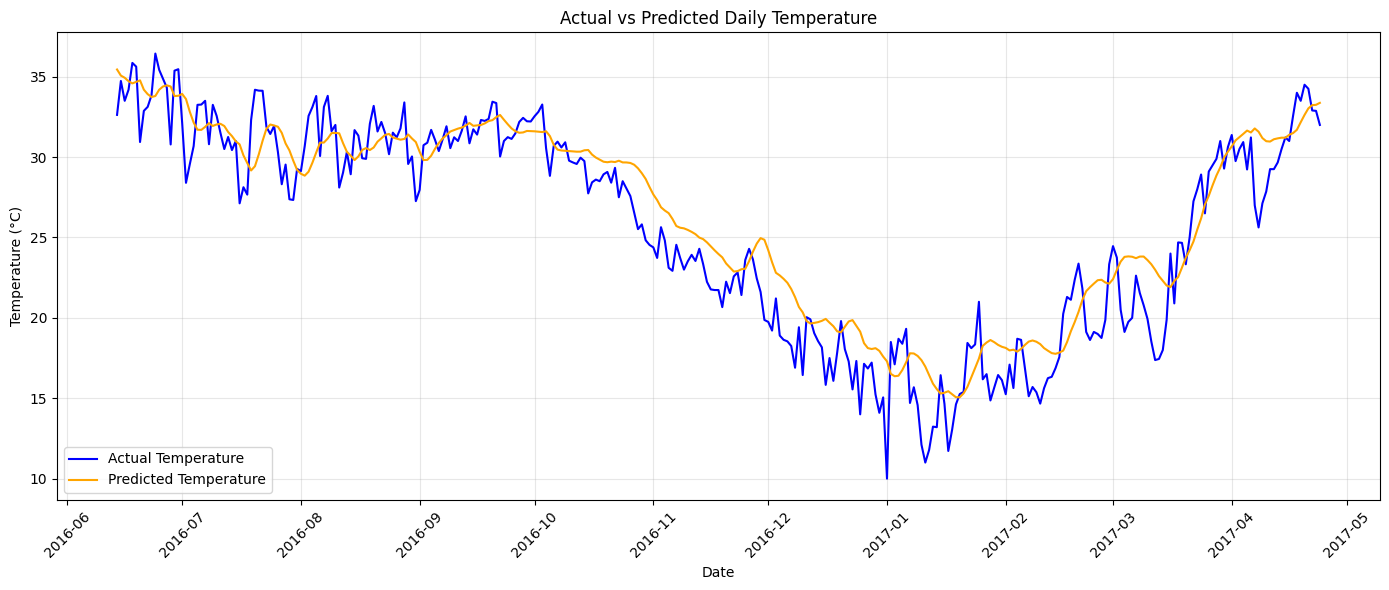

In [18]:
test_dates = df["date"].iloc[split_idx:].reset_index(drop=True)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test_actual,
    label="Actual Temperature",
    color="blue"
)

plt.plot(
    test_dates,
    y_pred_actual,
    label="Predicted Temperature",
    color="orange"
)

plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
# Start with the last 30 days of historical data
current_sequence = scaled_values[-LOOKBACK:].copy()

last_date = df["date"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

future_predictions = []
last_weather = scaled_values[-1].copy()

for future_date in future_dates:
    next_temp_scaled = model.predict(
        current_sequence[np.newaxis, :, :],
        verbose=0
    )[0, 0]

    next_temp = inverse_temperature([next_temp_scaled])[0]
    future_predictions.append(next_temp)

    next_row = last_weather.copy()
    next_row[target_idx] = next_temp_scaled

    current_sequence = np.vstack([
        current_sequence[1:],
        next_row
    ])

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Temperature_C": future_predictions
})

display(forecast_df.round(2))

,Date,Predicted_Temperature_C
0,2017-04-25,33.39
1,2017-04-26,33.48
2,2017-04-27,33.59
3,2017-04-28,33.71
4,2017-04-29,33.82
5,2017-04-30,33.94
6,2017-05-01,34.07


In [20]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred_scaled = model.predict(X_test, verbose=0)

y_test_actual = inverse_temperature(y_test)
y_pred_actual = inverse_temperature(y_pred_scaled)

mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
r2 = r2_score(y_test_actual, y_pred_actual)

mape = np.mean(
    np.abs(
        (y_test_actual - y_pred_actual) /
        np.maximum(np.abs(y_test_actual), 1e-8)
    )
) * 100

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score", "MAPE"],
    "Value": [
        round(mae, 4),
        round(rmse, 4),
        round(r2, 4),
        round(mape, 2)
    ],
    "Interpretation": [
        "Lower is better (°C)",
        "Lower is better (°C)",
        "Closer to 1 is generally better",
        "Lower is better (%)"
    ]
})

display(metrics_df)

,Metric,Value,Interpretation
0,MAE,1.8732,Lower is better (°C)
1,RMSE,2.3148,Lower is better (°C)
2,R2 Score,0.8760,Closer to 1 is generally better
3,MAPE,8.8000,Lower is better (%)


In [21]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_scaled = model.predict(X_test, verbose=0)

y_actual = inverse_temperature(y_test)
y_predicted = inverse_temperature(y_pred_scaled)

mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))
r2 = r2_score(y_actual, y_predicted)

mape = np.mean(
    np.abs((y_actual - y_predicted) / np.maximum(np.abs(y_actual), 1e-8))
) * 100

accuracy = max(0, 100 - mape)

print(f"MAE: {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")
print(f"R2 Score: {r2:.4f}")
print(f"Approximate Forecast Accuracy: {accuracy:.2f}%")

MAE: 1.87 °C
RMSE: 2.31 °C
R2 Score: 0.8760
Approximate Forecast Accuracy: 91.20%


In [22]:
comparison_df = pd.DataFrame({
    "Date": test_dates,
    "Actual_Temperature": y_actual,
    "Predicted_Temperature": y_predicted
})

comparison_df["Absolute_Error"] = abs(
    comparison_df["Actual_Temperature"] -
    comparison_df["Predicted_Temperature"]
)

comparison_df["Error_Percentage"] = (
    comparison_df["Absolute_Error"] /
    comparison_df["Actual_Temperature"].abs().clip(lower=0.1)
) * 100

display(comparison_df.head(20))

,Date,Actual_Temperature,Predicted_Temperature,Absolute_Error,Error_Percentage
0,2016-06-14,32.625001,35.448388,2.823388,8.654062
1,2016-06-15,34.733334,35.069756,0.336422,0.968586
2,2016-06-16,33.500000,34.933753,1.433753,4.279861
3,2016-06-17,34.187500,34.722627,0.535127,1.565272
4,2016-06-18,35.857143,34.583508,1.273635,3.551971
5,2016-06-19,35.625001,34.678005,0.946996,2.658234
6,2016-06-20,30.937500,34.772367,3.834868,12.395531
7,2016-06-21,32.875000,34.191797,1.316797,4.005466
8,2016-06-22,33.125000,33.913569,0.788569,2.380584
9,2016-06-23,33.846154,33.736348,0.109806,0.324427


In [23]:
print("WEATHER FORECASTING MODEL REPORT")
print("-" * 35)
print(f"MAE       : {mae:.3f} °C")
print(f"RMSE      : {rmse:.3f} °C")
print(f"R2 Score  : {r2:.3f}")
print(f"Approx. Accuracy: {accuracy:.2f}%")

if mae < 1:
    print("Conclusion: Low average absolute temperature error.")
elif mae < 2:
    print("Conclusion: Moderate average absolute temperature error.")
else:
    print("Conclusion: Further model improvement may be useful.")

if r2 > 0:
    print("The model explains some variation in test temperatures.")
else:
    print("The model does not outperform the test-set mean in R2 terms.")

WEATHER FORECASTING MODEL REPORT
-----------------------------------
MAE       : 1.873 °C
RMSE      : 2.315 °C
R2 Score  : 0.876
Approx. Accuracy: 91.20%
Conclusion: Moderate average absolute temperature error.
The model explains some variation in test temperatures.
